In [4]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.cluster import DBSCAN

import hdbscan

In [7]:
embeddings = np.memmap(
    "../data/processed/log_embeddings.memmap",
    dtype="float32",
    mode="r",
    shape=(121161, 384)  
)

print(f"✅ Embeddings shape: {embeddings.shape}")

X = embeddings[:5000]

✅ Embeddings shape: (121161, 384)


In [8]:
db = DBSCAN(eps=0.5, min_samples=10)

labels_db = db.fit_predict(X)

print("Clusters DBSCAN:", len(set(labels_db)))

Clusters DBSCAN: 1


In [9]:
clusterer = hdbscan.HDBSCAN(
    min_cluster_size=10
)

labels_hdb = clusterer.fit_predict(X)

print("Clusters HDBSCAN:", len(set(labels_hdb)))

Clusters HDBSCAN: 1


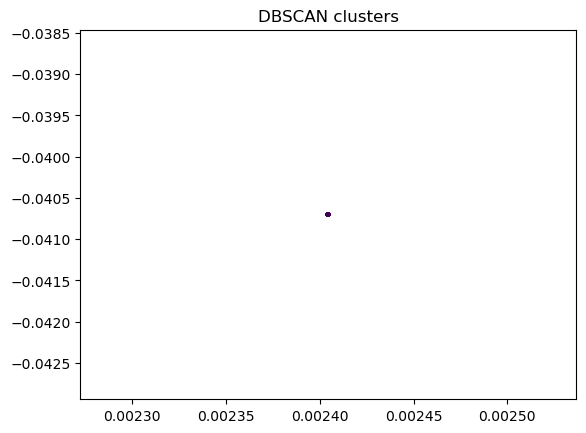

In [10]:
plt.scatter(X[:,0], X[:,1], c=labels_db, s=5)

plt.title("DBSCAN clusters")

plt.show()

In [11]:
# Version simple et rapide pour commencer
import numpy as np
from sklearn.cluster import DBSCAN
from sklearn.preprocessing import StandardScaler

# 1. Charger les embeddings
embeddings = np.memmap(
    "../data/processed/log_embeddings.memmap",
    dtype="float32",
    mode="r",
    shape=(121161, 384)  # À ajuster si nécessaire
)

print(f"✅ Embeddings shape: {embeddings.shape}")

# 2. Prendre un échantillon
X = embeddings[:10000].copy()
print(f"📊 Échantillon: {X.shape}")

# 3. Normaliser
X_scaled = StandardScaler().fit_transform(X)

# 4. DBSCAN avec paramètres de base
db = DBSCAN(eps=0.5, min_samples=10, n_jobs=-1)
labels = db.fit_predict(X_scaled)

# 5. Résultats
n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
n_noise = np.sum(labels == -1)

print(f"\n📊 RÉSULTATS")
print("="*30)
print(f"Nombre de clusters: {n_clusters}")
print(f"Points de bruit: {n_noise} ({n_noise/len(labels)*100:.1f}%)")

if n_clusters > 0:
    print(f"Taille des clusters: {np.bincount(labels[labels >= 0])}")

✅ Embeddings shape: (121161, 384)
📊 Échantillon: (10000, 384)

📊 RÉSULTATS
Nombre de clusters: 2
Points de bruit: 0 (0.0%)
Taille des clusters: [9984   16]


📁 Taille fichier: 11.10 GB
📊 Échantillons détectés: 7,224,549
🔢 Dimension des embeddings: 384

📊 Échantillon pour clustering: (10000, 384)

🔍 Application de DBSCAN...
eps=0.3, min_samples=5: clusters=2, bruit=0.0%
eps=0.3, min_samples=10: clusters=2, bruit=0.0%
eps=0.3, min_samples=20: clusters=1, bruit=0.2%
eps=0.3, min_samples=50: clusters=1, bruit=0.2%
eps=0.5, min_samples=5: clusters=2, bruit=0.0%
eps=0.5, min_samples=10: clusters=2, bruit=0.0%
eps=0.5, min_samples=20: clusters=1, bruit=0.2%
eps=0.5, min_samples=50: clusters=1, bruit=0.2%
eps=0.7, min_samples=5: clusters=2, bruit=0.0%
eps=0.7, min_samples=10: clusters=2, bruit=0.0%
eps=0.7, min_samples=20: clusters=1, bruit=0.2%
eps=0.7, min_samples=50: clusters=1, bruit=0.2%
eps=1.0, min_samples=5: clusters=2, bruit=0.0%
eps=1.0, min_samples=10: clusters=2, bruit=0.0%
eps=1.0, min_samples=20: clusters=1, bruit=0.2%
eps=1.0, min_samples=50: clusters=1, bruit=0.2%

🏆 Meilleurs paramètres: {'eps': 0.3, 'min_samples': 5}
📊 Clusters tr

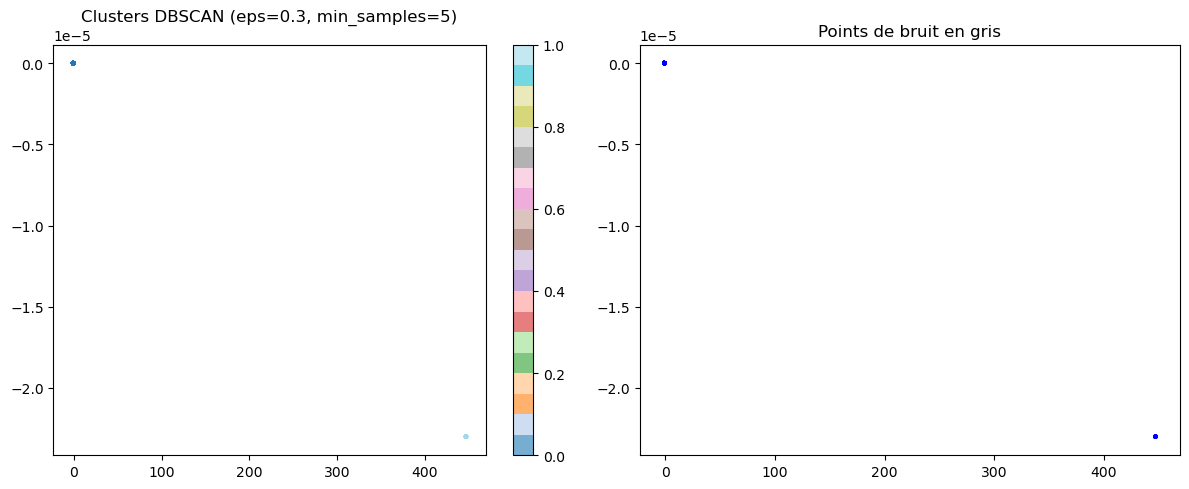


📊 Distribution des clusters:
  Cluster 0: 9,981 points (99.8%)
  Cluster 1: 19 points (0.2%)


In [12]:
import numpy as np
from sklearn.cluster import DBSCAN
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

# 1. Chargement avec calcul automatique de la taille
import os

file_path = "../data/processed/log_embeddings.memmap"
file_size = os.path.getsize(file_path)
embedding_dim = 384
dtype_size = np.dtype('float32').itemsize

n_samples = file_size // (embedding_dim * dtype_size)
print(f"📁 Taille fichier: {file_size / 1e9:.2f} GB")
print(f"📊 Échantillons détectés: {n_samples:,}")
print(f"🔢 Dimension des embeddings: {embedding_dim}")

# 2. Chargement avec la bonne forme
embeddings = np.memmap(
    file_path,
    dtype="float32",
    mode="r",
    shape=(n_samples, embedding_dim)
)

# 3. Échantillonnage pour le clustering
sample_size = min(10000, n_samples)  # Prendre 10k max pour DBSCAN
indices = np.random.choice(n_samples, sample_size, replace=False)
X_sample = embeddings[indices].copy()

print(f"\n📊 Échantillon pour clustering: {X_sample.shape}")

# 4. Normalisation (important pour DBSCAN)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_sample)

# 5. DBSCAN avec paramètres adaptés
print("\n🔍 Application de DBSCAN...")

# Ajustez ces paramètres selon vos besoins
eps_values = [0.3, 0.5, 0.7, 1.0]
min_samples_values = [5, 10, 20, 50]

best_score = -1
best_params = {}

for eps in eps_values:
    for min_samples in min_samples_values:
        db = DBSCAN(eps=eps, min_samples=min_samples, n_jobs=-1)
        labels = db.fit_predict(X_scaled)
        
        n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
        n_noise = np.sum(labels == -1)
        noise_ratio = n_noise / len(labels)
        
        # Score: favoriser plus de clusters avec peu de bruit
        score = n_clusters * (1 - noise_ratio)
        
        print(f"eps={eps}, min_samples={min_samples}: clusters={n_clusters}, bruit={noise_ratio:.1%}")
        
        if score > best_score:
            best_score = score
            best_params = {'eps': eps, 'min_samples': min_samples}
            best_labels = labels

print(f"\n🏆 Meilleurs paramètres: {best_params}")
print(f"📊 Clusters trouvés: {len(set(best_labels)) - (1 if -1 in best_labels else 0)}")

# 6. Visualisation avec PCA
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
scatter = plt.scatter(X_pca[:, 0], X_pca[:, 1], c=best_labels, cmap='tab20', s=5, alpha=0.6)
plt.title(f'Clusters DBSCAN (eps={best_params["eps"]}, min_samples={best_params["min_samples"]})')
plt.colorbar(scatter)

plt.subplot(1, 2, 2)
# Points de bruit en évidence
colors = ['gray' if l == -1 else 'blue' for l in best_labels]
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=colors, s=5, alpha=0.6)
plt.title('Points de bruit en gris')

plt.tight_layout()
plt.show()

# 7. Statistiques détaillées
unique, counts = np.unique(best_labels, return_counts=True)
print("\n📊 Distribution des clusters:")
for cluster, count in zip(unique, counts):
    if cluster == -1:
        print(f"  Bruit (-1): {count:,} points ({count/len(best_labels)*100:.1f}%)")
    else:
        print(f"  Cluster {cluster}: {count:,} points ({count/len(best_labels)*100:.1f}%)")